# **Qubit Initialization and Measurement using Quantum Gate Simulation**

**Aim**: To initialize a single qubit in computational basis states ($|0\rangle$ and $|1\rangle$) and evaluate its measurement probabilities using Qiskit Aer simulation

**Theory:**
 In Qiskit, qubits default to the ground state $|0\rangle$ and can be transformed using unitary operations such as the Pauli-X gate, which acts as a quantum NOT gate to flip $|0\rangle$ into $|1\rangle$.

  Quantum gates deterministically manipulate the probability amplitudes of the state vector without collapsing the state prior to measurement.
  
  Upon measurement, the wavefunction collapses into a classical bit according to the Born rule, yielding empirical statistics sampled across multiple shots via AerSimulator

# Prerequisites & Package Installation

 Run this cell to install Qiskit, the Aer simulation framework, and Matplotlib for plotting measurement results.

In [ ]:
!pip install qiskit qiskit-aer matplotlib

# **Program Code:**

State |0⟩ Measurement Counts: {'0': 1024}
Circuit Diagram:
     ┌─┐
  q: ┤M├
     └╥┘
c: 1/═╩═
      0 
-----------------------------------
State |1⟩ Measurement Counts: {'1': 1024}
Circuit Diagram:
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
-----------------------------------


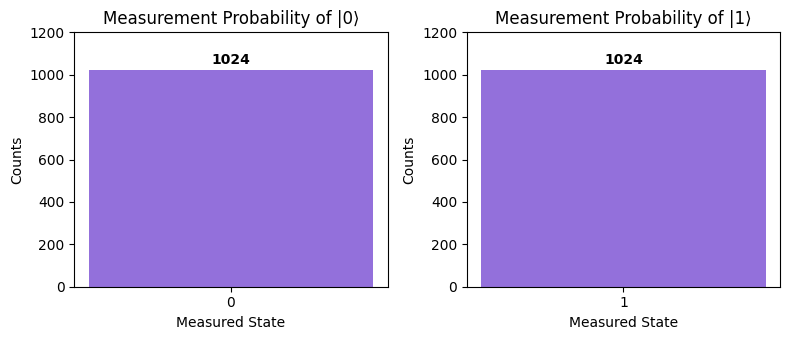

In [3]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

def run_experiment():
    simulator = AerSimulator()
    states = ["0", "1"]
    results = {}

    # 1. Circuit Creation & Simulation
    for state in states:
        qc = QuantumCircuit(1, 1)
        if state == "1":
            qc.x(0)  # Apply Pauli-X gate
        qc.measure(0, 0)

        # Transpile & run on Qiskit Aer
        transpiled_qc = transpile(qc, simulator)
        counts = simulator.run(transpiled_qc, shots=1024).result().get_counts()
        results[state] = counts

        print(f"State |{state}⟩ Measurement Counts:", counts)
        print("Circuit Diagram:")
        print(qc.draw(output='text'))
        print("-" * 35)

    # 2. Result Image (Histogram Plot)
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
    for ax, state in zip(axes, states):
        counts = results[state]
        ax.bar(counts.keys(), counts.values(), color='mediumpurple', width=0.4)
        ax.set_title(f"Measurement Probability of |{state}⟩")
        ax.set_xlabel("Measured State")
        ax.set_ylabel("Counts")
        ax.set_ylim(0, 1200)
        for k, v in counts.items():
            ax.text(k, v + 25, str(v), ha='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

# Execute experiment
run_experiment()

# 📊 Experimental Results

The histogram below displays the measurement probability distribution obtained from executing **1,024 shots** on the `AerSimulator` backend. It contrasts the deterministic ground state $|0\rangle$ against the excited state $|1\rangle$ prepared via the Pauli-X gate.
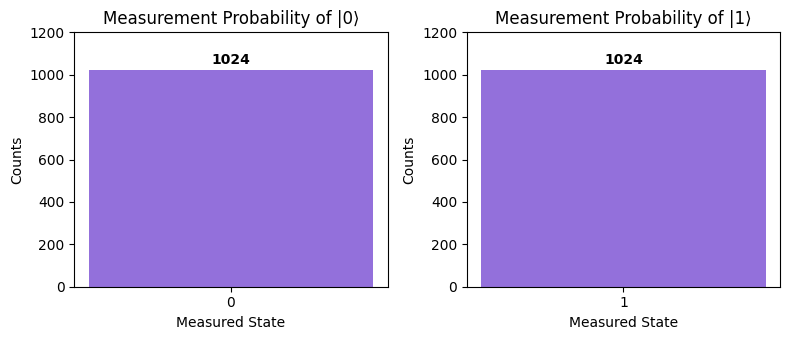

# **Observation**:

Initializing state $|0\rangle$ yields a 100% measurement outcome for bit '0', whereas applying the Pauli-X gate deterministically flips the state to $|1\rangle$, producing a 100% measurement outcome for bit '1'